In [1]:

# Week 3: Statistical Analysis and Predictive Modeling

data(iris)

# View the first six rows
head(iris)

# Check dataset structure
str(iris)

# Summary statistics
summary(iris)

# Count each flower species
table(iris$Species)

# Check missing values
colSums(is.na(iris))


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


'data.frame':	150 obs. of  5 variables:
 $ Sepal.Length: num  5.1 4.9 4.7 4.6 5 5.4 4.6 5 4.4 4.9 ...
 $ Sepal.Width : num  3.5 3 3.2 3.1 3.6 3.9 3.4 3.4 2.9 3.1 ...
 $ Petal.Length: num  1.4 1.4 1.3 1.5 1.4 1.7 1.4 1.5 1.4 1.5 ...
 $ Petal.Width : num  0.2 0.2 0.2 0.2 0.2 0.4 0.3 0.2 0.2 0.1 ...
 $ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 1 1 1 1 1 1 1 1 ...


  Sepal.Length    Sepal.Width     Petal.Length    Petal.Width   
 Min.   :4.300   Min.   :2.000   Min.   :1.000   Min.   :0.100  
 1st Qu.:5.100   1st Qu.:2.800   1st Qu.:1.600   1st Qu.:0.300  
 Median :5.800   Median :3.000   Median :4.350   Median :1.300  
 Mean   :5.843   Mean   :3.057   Mean   :3.758   Mean   :1.199  
 3rd Qu.:6.400   3rd Qu.:3.300   3rd Qu.:5.100   3rd Qu.:1.800  
 Max.   :7.900   Max.   :4.400   Max.   :6.900   Max.   :2.500  
       Species  
 setosa    :50  
 versicolor:50  
 virginica :50  
                
                
                


    setosa versicolor  virginica 
        50         50         50 

Sepal.Length  Sepal.Width Petal.Length  Petal.Width      Species 
           0            0            0            0            0

In [2]:

# STEP 3: STATISTICAL ANALYSIS

# 1. Calculate mean, median, and standard deviation
mean(iris$Sepal.Length)
median(iris$Sepal.Length)
sd(iris$Sepal.Length)

# 2. Correlation between sepal length and petal length
cor.test(iris$Sepal.Length, iris$Petal.Length,
         method = "pearson")

# 3. Normality test for petal length
shapiro.test(iris$Petal.Length)

# 4. Compare petal length by flower species
aggregate(Petal.Length ~ Species,
          data = iris,
          FUN = mean)


[1] 5.843333

[1] 5.8

[1] 0.8280661


	Pearson's product-moment correlation

data:  iris$Sepal.Length and iris$Petal.Length
t = 21.646, df = 148, p-value < 2.2e-16
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.8270363 0.9055080
sample estimates:
      cor 
0.8717538 



	Shapiro-Wilk normality test

data:  iris$Petal.Length
W = 0.87627, p-value = 7.412e-10


Species,Petal.Length
<fct>,<dbl>
setosa,1.462
versicolor,4.260
virginica,5.552


In [3]:

# STEP 4: HYPOTHESIS TESTING USING ANOVA

# H0: Mean petal length is equal across all three species.
# H1: At least one species has a different mean petal length.

# Perform one-way ANOVA
anova_model <- aov(Petal.Length ~ Species, data = iris)

# Display ANOVA results
summary(anova_model)

# Compare the mean petal length of each species
aggregate(Petal.Length ~ Species, data = iris, mean)

# Check ANOVA assumptions using residuals
shapiro.test(residuals(anova_model))

# Check equal variance across species
bartlett.test(Petal.Length ~ Species, data = iris)


             Df Sum Sq Mean Sq F value Pr(>F)    
Species       2  437.1  218.55    1180 <2e-16 ***
Residuals   147   27.2    0.19                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Species,Petal.Length
<fct>,<dbl>
setosa,1.462
versicolor,4.260
virginica,5.552



	Shapiro-Wilk normality test

data:  residuals(anova_model)
W = 0.98108, p-value = 0.03676



	Bartlett test of homogeneity of variances

data:  Petal.Length by Species
Bartlett's K-squared = 55.423, df = 2, p-value = 9.229e-13


In [4]:

# STEP 5: MULTINOMIAL LOGISTIC REGRESSION

# Install package (only needed once per runtime)
install.packages("nnet")

library(nnet)

set.seed(123)

# Split data into 80% training and 20% testing
train_index <- sample(1:nrow(iris), 0.8 * nrow(iris))
train_data <- iris[train_index, ]
test_data <- iris[-train_index, ]

# Build the classification model
model <- multinom(
  Species ~ Sepal.Length + Sepal.Width +
    Petal.Length + Petal.Width,
  data = train_data,
  trace = FALSE
)

# View model results
summary(model)

# Predict flower species on test data
predictions <- predict(model, newdata = test_data)

# Compare actual and predicted species
table(Actual = test_data$Species,
      Predicted = predictions)

# Calculate accuracy
accuracy <- mean(predictions == test_data$Species)
print(paste("Test Accuracy:", round(accuracy * 100, 2), "%"))


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Call:
multinom(formula = Species ~ Sepal.Length + Sepal.Width + Petal.Length + 
    Petal.Width, data = train_data, trace = FALSE)

Coefficients:
           (Intercept) Sepal.Length Sepal.Width Petal.Length Petal.Width
versicolor    48.28722    -24.64201   -24.27893      47.2458    3.130761
virginica    -83.41388    -58.94158   -60.89885     117.6548   65.130414

Std. Errors:
           (Intercept) Sepal.Length Sepal.Width Petal.Length Petal.Width
versicolor    106.5370     35.94035    27.03289     48.92239    32.11012
virginica     105.9997     46.24989    32.56462     41.91175    29.42979

Residual Deviance: 1.474475 
AIC: 21.47447 

            Predicted
Actual       setosa versicolor virginica
  setosa         10          0         0
  versicolor      0         14         1
  virginica       0          0         5

[1] "Test Accuracy: 96.67 %"


In [5]:

# STEP 6: 5-FOLD CROSS-VALIDATION

install.packages("caret")
library(caret)

set.seed(123)

# Create 5 folds for cross-validation
folds <- createFolds(iris$Species, k = 5, list = TRUE)

# Store accuracy for each fold
fold_accuracy <- numeric(length(folds))

for (i in seq_along(folds)) {

  # Separate training and validation data
  validation_index <- folds[[i]]
  train_fold <- iris[-validation_index, ]
  validation_fold <- iris[validation_index, ]

  # Train the multinomial logistic regression model
  fold_model <- nnet::multinom(
    Species ~ Sepal.Length + Sepal.Width +
      Petal.Length + Petal.Width,
    data = train_fold,
    trace = FALSE
  )

  # Predict validation data
  fold_predictions <- predict(
    fold_model,
    newdata = validation_fold
  )

  # Calculate accuracy
  fold_accuracy[i] <- mean(
    fold_predictions == validation_fold$Species
  )
}

# Display accuracy for each fold
print(fold_accuracy)

# Calculate average cross-validation accuracy
mean_accuracy <- mean(fold_accuracy) * 100
print(paste(
  "Mean 5-Fold Cross-Validation Accuracy:",
  round(mean_accuracy, 2), "%"
))


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘pROC’, ‘recipes’, ‘reshape2’


Loading required package: ggplot2

Loading required package: lattice



[1] 1.0000000 0.9666667 1.0000000 0.9666667 0.9333333
[1] "Mean 5-Fold Cross-Validation Accuracy: 97.33 %"


In [6]:

# STEP 7: MODEL PERFORMANCE EVALUATION

# Predict using the training/test split from Step 5
predictions <- factor(
  predict(model, newdata = test_data),
  levels = levels(test_data$Species)
)

actual <- factor(
  test_data$Species,
  levels = levels(test_data$Species)
)

# Confusion matrix
conf_matrix <- confusionMatrix(
  predictions,
  actual
)

print(conf_matrix)

# Extract overall accuracy
print(conf_matrix$overall["Accuracy"])

# Extract class-wise precision and recall
print(conf_matrix$byClass[, c(
  "Sensitivity",
  "Pos Pred Value",
  "F1"
)])


Confusion Matrix and Statistics

            Reference
Prediction   setosa versicolor virginica
  setosa         10          0         0
  versicolor      0         14         0
  virginica       0          1         5

Overall Statistics
                                          
               Accuracy : 0.9667          
                 95% CI : (0.8278, 0.9992)
    No Information Rate : 0.5             
    P-Value [Acc > NIR] : 2.887e-08       
                                          
                  Kappa : 0.9464          
                                          
 Mcnemar's Test P-Value : NA              

Statistics by Class:

                     Class: setosa Class: versicolor Class: virginica
Sensitivity                 1.0000            0.9333           1.0000
Specificity                 1.0000            1.0000           0.9600
Pos Pred Value              1.0000            1.0000           0.8333
Neg Pred Value              1.0000            0.9375           1.0000
P

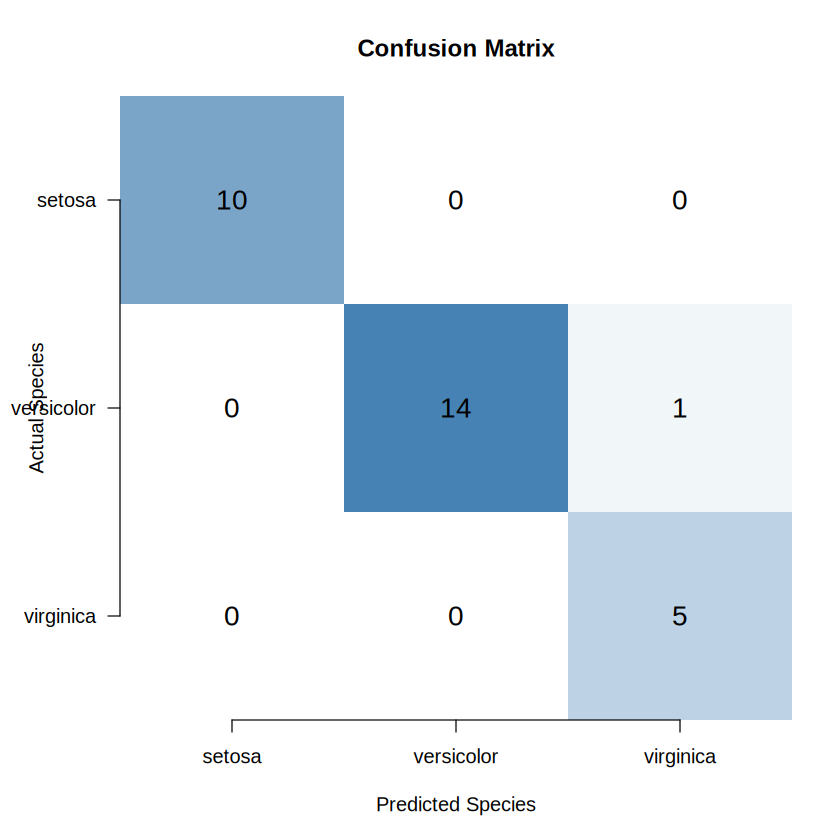

In [8]:

# CLEAN MODEL DIAGNOSTICS

# Create confusion matrix
conf_table <- table(
  Actual = test_data$Species,
  Predicted = predictions
)

# Set clean graph layout
par(mfrow = c(1, 1), mar = c(5, 5, 4, 2))

# Plot confusion matrix as a clean heatmap
image(
  x = 1:ncol(conf_table),
  y = 1:nrow(conf_table),
  z = t(conf_table[nrow(conf_table):1, ]),
  col = colorRampPalette(c("white", "steelblue"))(100),
  axes = FALSE,
  xlab = "Predicted Species",
  ylab = "Actual Species",
  main = "Confusion Matrix"
)

axis(1, at = 1:3, labels = colnames(conf_table))
axis(2, at = 1:3, labels = rev(rownames(conf_table)), las = 1)

# Add numbers inside each cell
for (i in 1:nrow(conf_table)) {
  for (j in 1:ncol(conf_table)) {
    text(j, nrow(conf_table) - i + 1,
         labels = conf_table[i, j], cex = 1.4)
  }
}


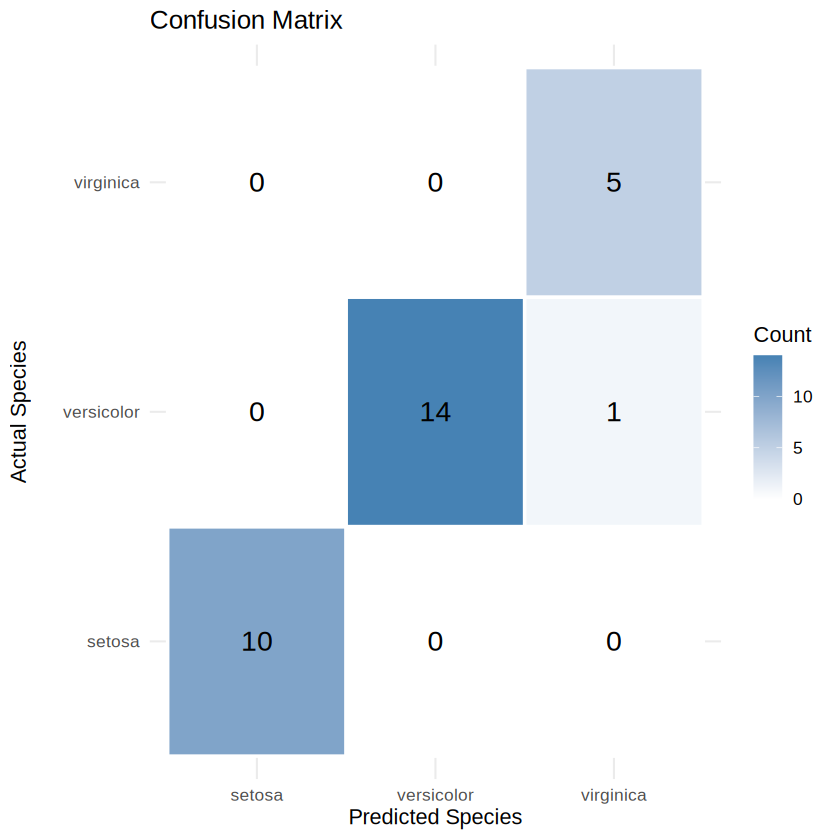

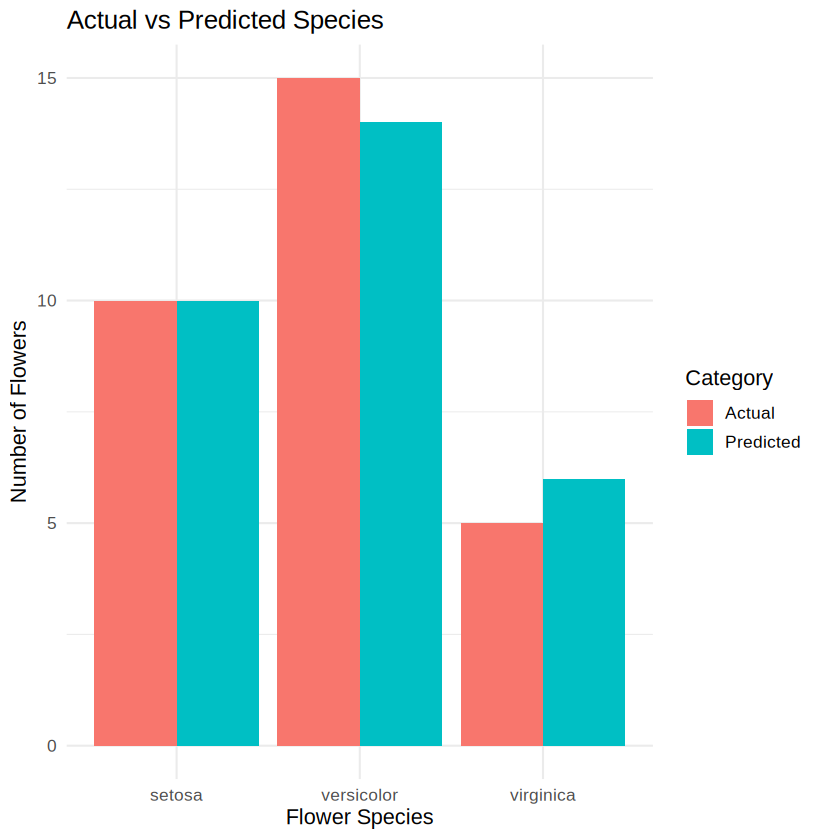

In [10]:

# STEP 8: CLEAN MODEL DIAGNOSTICS

# Create confusion matrix
conf_table <- table(
  Actual = test_data$Species,
  Predicted = predictions
)

# GRAPH 1: Clean confusion matrix
par(mfrow = c(1, 1))

library(ggplot2)

conf_df <- as.data.frame(conf_table)

ggplot(conf_df, aes(x = Predicted, y = Actual, fill = Freq)) +
  geom_tile(color = "white", linewidth = 1) +
  geom_text(aes(label = Freq), size = 6) +
  scale_fill_gradient(low = "white", high = "steelblue") +
  labs(
    title = "Confusion Matrix",
    x = "Predicted Species",
    y = "Actual Species",
    fill = "Count"
  ) +
  theme_minimal(base_size = 13)

# GRAPH 2: Actual vs Predicted counts
bar_df <- rbind(
  data.frame(
    Species = rownames(conf_table),
    Count = rowSums(conf_table),
    Type = "Actual"
  ),
  data.frame(
    Species = colnames(conf_table),
    Count = colSums(conf_table),
    Type = "Predicted"
  )
)

ggplot(bar_df, aes(x = Species, y = Count, fill = Type)) +
  geom_col(position = "dodge") +
  labs(
    title = "Actual vs Predicted Species",
    x = "Flower Species",
    y = "Number of Flowers",
    fill = "Category"
  ) +
  theme_minimal(base_size = 13)


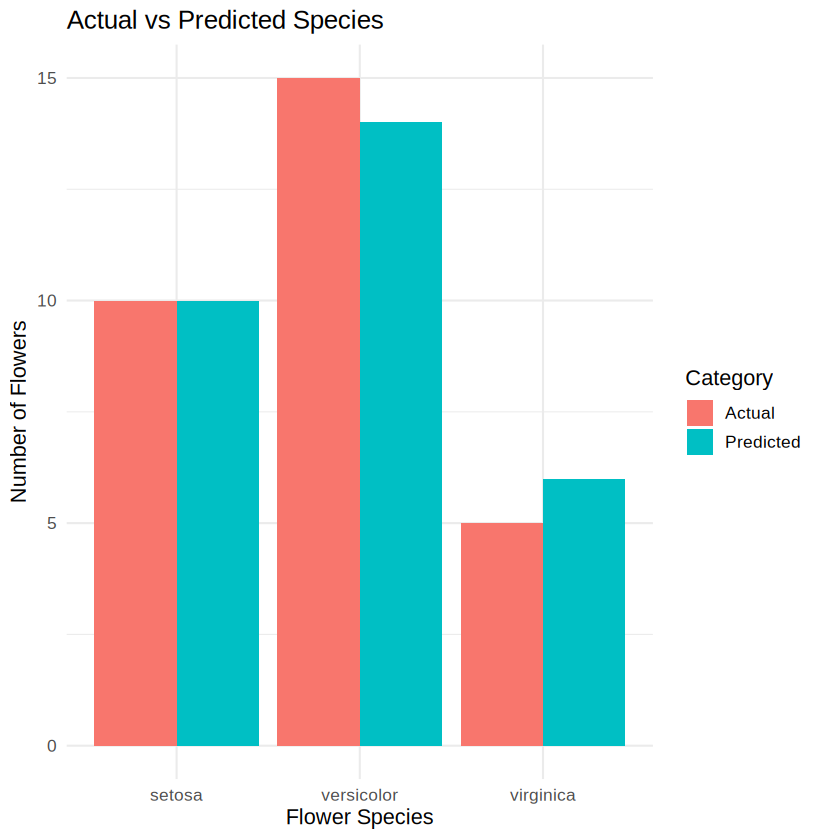

In [12]:

bar_df <- rbind(
  data.frame(
    Species = rownames(conf_table),
    Count = rowSums(conf_table),
    Type = "Actual"
  ),
  data.frame(
    Species = colnames(conf_table),
    Count = colSums(conf_table),
    Type = "Predicted"
  )
)

ggplot(bar_df, aes(x = Species, y = Count, fill = Type)) +
  geom_col(position = "dodge") +
  labs(
    title = "Actual vs Predicted Species",
    x = "Flower Species",
    y = "Number of Flowers",
    fill = "Category"
  ) +
  theme_minimal(base_size = 13)
